# Lab 1: Telco Customer Churn Analysis

## 1. Introduction

This lab focuses on preprocessing and exploring the Telco Customer Churn dataset using Python. The purpose is to understand customer information and explore the relationship between customer characteristics, services, payment methods, and customer churn. The analysis includes data cleaning, checking data types, identifying missing values, and visualizing patterns related to churn.

## 2. Loading the Dataset

The dataset is loaded into a pandas DataFrame. A DataFrame is a table that stores data in rows and columns, making it easier to inspect and analyze.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Display the last five rows
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### Interpretation of the Head and Tail

The `head()` output displays the first five customer records, while the `tail()` output displays the last five customer records. Both outputs help us inspect the dataset, confirm the column names, and check that the data has loaded correctly.

## 3. Data Preprocessing

Data preprocessing prepares the dataset for analysis. In this section, we will inspect the data types, convert the Churn column from Yes/No to 1/0, and check for missing values.

In [4]:
# Display the data type of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [ ]:
# Convert Churn values from Yes/No to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Display the updated Churn values
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [ ]:
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# Check for blank values in TotalCharges
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [8]:
# Convert TotalCharges to numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Count missing values in each column
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
# Check the customers with missing TotalCharges
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [11]:
# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check missing values again
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Handling Missing Values**

The dataset contained 11 missing values in the `TotalCharges` column. After checking these records, I found that all 11 customers had a tenure of zero months. Since they had zero months of recorded service, I replaced the missing `TotalCharges` values with 0. This allows us to continue the analysis without deleting these customer records. This treatment assumes that these customers had not accumulated any total charges.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset by examining its structure, summary statistics, and patterns. In this section, we will explore the number of records, the types of data, and the distribution of important variables.

In [13]:
# Display the number of rows and columns
df.shape

(7043, 21)

In [14]:
# Display the data type of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [15]:
# Display summary statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


### Interpretation of Summary Statistics

The dataset contains 7,043 customer records. The average customer tenure is approximately 32.37 months, and the average monthly charge is 64.76. The average total charge is 2,279.73. The mean of the `Churn` column is approximately 0.2654, indicating that about 26.54% of customers left the company. Also, approximately 16.21% of customers are senior citizens. These statistics provide an overview of customer characteristics and churn in the dataset.

In [16]:
# Count customers who stayed and customers who left
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

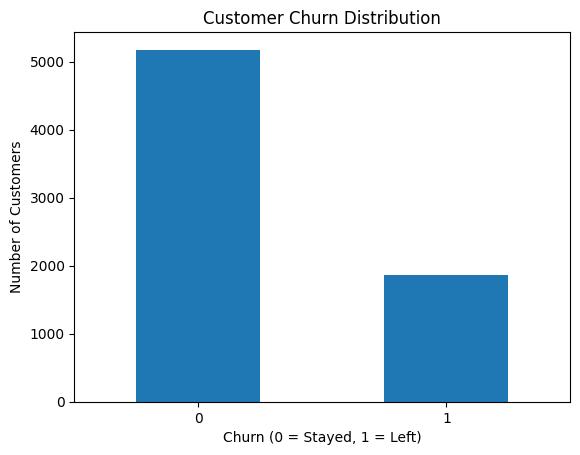

In [17]:
import matplotlib.pyplot as plt

# Count customers in each churn category
churn_counts = df["Churn"].value_counts().sort_index()

# Create a bar chart
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Interpretation of Churn Distribution

The bar chart shows that 5,174 customers stayed with the company, while 1,869 customers left. Therefore, most customers stayed, and approximately 26.54% left the company. This indicates that customer churn is an important area to investigate further.